In [4]:
from PIL import Image
img = Image.open("lab2_pic.jpg")

In [5]:
#1. Thây đổi độ sáng: Tăng hoặc giảm độ sáng của toàn bộ hình ảnh bằng cách cộng hoặc trừ một giá trị cố định cho mỗi điểm ảnh.

import numpy as np

img = np.array(img, dtype=np.uint8)

img_increased_light = img.astype(np.int16) + 20
img_decreased_light = img.astype(np.int16) - 20

img_increased_light = np.clip(
    img_increased_light, 0, 255
).astype(np.uint8)

img_decreased_light = np.clip(
    img_decreased_light, 0, 255
).astype(np.uint8)

img_increased_light = Image.fromarray(
    img_increased_light, "RGB"
)
img_decreased_light = Image.fromarray(
    img_decreased_light, "RGB"
)

img_increased_light.save("img_increased_light.jpg")
img_decreased_light.save("img_decreased_light.jpg")

In [6]:
#2. Thay đổi độ tương phản: Tăng hoặc giảm độ tương phản bằng cách nhân một điểm ảnh với một hằng số.

img_increased_contrac = img.astype(np.int16)*1.5
img_decreased_contrac = img.astype(np.int16)*0.3

img_increased_contrac = np.clip(img_increased_contrac,0,255)
img_increased_contrac = Image.fromarray(img_increased_contrac.astype(np.uint8), "RGB")
img_decreased_contrac = Image.fromarray(img_decreased_contrac.astype(np.uint8), "RGB")

img_increased_contrac.save("img_increased_contrac.jpg")
img_decreased_contrac.save("img_decreased_contrac.jpg")

In [7]:
#3. Biến đổi âm bản: Đảo ngược các giá trị điểm ảnh, tạo ra âm bản.
img_negative = 255 - img.astype(np.int16)
img_negative = Image.fromarray(img_negative.astype(np.uint8), "RGB")
img_negative.save("img_negative.jpg")

In [8]:
#4. Cắt ngưỡng: Tạo ảnh nhị phân bằng cách so sánh giá trị mỗi điểm ảnh với một ngưỡng nhất định.
img_threshold = Image.open("lab2_pic.jpg").convert("L")

img_threshold = np.array(img_threshold)
T = 128

img_threshold = np.where(img_threshold >= T, 255, 0)
img_threshold = img_threshold.astype(np.uint8)
img_threshold = Image.fromarray(img_threshold)
img_threshold.save("img_threshold.jpg")

In [9]:
#5. Lọc trung bình: Làm mờ ảnh bằng cách tính giá trị trung bình của các điểm ảnh trong một vùng lân cận.
img = Image.open("lab2_pic.jpg").convert("RGB")

img_array = np.array(img, dtype=np.float32)

height, width, channels = img_array.shape
result = np.zeros_like(img_array)

for c in range(channels):
    for y in range(1, height - 1):
        for x in range(1, width - 1):
            region = img_array[
                y-1:y+2,
                x-1:x+2,
                c
            ]
            result[y, x, c] = np.mean(region)
result = np.clip(result, 0, 255).astype(np.uint8)
Image.fromarray(result).save("img_mean_filter.jpg")

In [10]:
from PIL import ImageFilter
result = img.filter(ImageFilter.BoxBlur(1))
result.save("img_boxblur_filter.jpg")

In [11]:
img = Image.open("lab2_pic.jpg")
img_gaussian = img.filter(ImageFilter.GaussianBlur(radius=10))
img_gaussian.save("img_gaussian.jpg")

In [12]:
img = Image.open("lab2_pic.jpg").convert("RGB")

# Kernel làm sắc nét
kernel_1 = [
     0, -1,  0,
    -1,  5, -1,
     0, -1,  0
]

kernel_2 = [
    -1, -1, -1,
    -1, 9 , -1,
    -1, -1, -1
]
# Áp dụng kernel
img_sharpen = img.filter(
    ImageFilter.Kernel(
        size=(3, 3),
        kernel=kernel_1,
        scale=1,
        offset=0
    )
)

img_sharpen_2 = img.filter(
    ImageFilter.Kernel(
        size=(3,3),
        kernel=kernel_2,
        scale=1,
        offset=0
    )
)

img_sharpen.save("img_sharpen.jpg")
img_sharpen_2.save("img_sharpen_2.jpg")

In [13]:
#6. Phát hiện cạnh: Sử dụng kernel Sobel, Prewitt để phát hiện các cạnh trong ảnh
# Kernel Sobel X và Y
Kx = [
    -1, 0, 1,
    -2, 0, 2,
    -1, 0, 1
]

Ky = [
    -1, -2, -1,
     0,  0,  0,
     1,  2,  1
]

# Tính gradient theo hai hướng
Gx = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kx,
    scale=1,
    offset=0
))
Gx = np.array(Gx)
Gy = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Ky,
    scale=1,
    offset=0
))
Gy = np.array(Gy)

# Kết hợp Sobel X + Y
G = np.sqrt(Gx**2 + Gy**2)

# Chuẩn hóa về khoảng 0–255
G = np.clip(G / (G.max() + 1e-8) * 255, 0, 255)
G = G.astype(np.uint8)

img_sobel = Image.fromarray(G)
img_sobel.save("img_sobel.jpg")

In [14]:
# Kernel Prewitt X và Y
Kx = [
    -1, 0, 1,
    -1, 0, 1,
    -1, 0, 1
]

Ky = [
    -1, -1, -1,
     0,  0,  0,
     1,  1,  1
]

# Tính gradient theo hai hướng
Gx = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kx,
    scale=1,
    offset=0
))
Gx = np.array(Gx)
Gy = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Ky,
    scale=1,
    offset=0
))
Gy = np.array(Gy)

# Kết hợp Sobel X + Y
G = np.sqrt(Gx**2 + Gy**2)

# Chuẩn hóa về khoảng 0–255
G = np.clip(G / (G.max() + 1e-8) * 255, 0, 255)
G = G.astype(np.uint8)

img_prewitt = Image.fromarray(G)
img_prewitt.save("img_prewitt.jpg")

In [15]:
#7. Tự thiết kế kernel: Tạo các kernel tùy chỉnh để đạt được các hiệu ứng khác nhau
Kernel_1 = [
    -2 , -1, 0,
    -1 , 1, 1,
    0 , 1, 2
]
img_k1 = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kernel_1,
    scale=1,
    offset=0
))
img_k1.save("img_k1.jpg")

In [16]:
Kernel_2 = [
    -1 , 1, 0,
    -1 , 1, 2,
    -1 , 1, 0
]
img_k2 = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kernel_2,
    scale=1,
    offset=0
))
img_k2.save("img_k2.jpg")

In [17]:
Kernel_3 = [
    1 , -1, 0,
    1 , -1, -1,
    1 , -1, 0
]
img_k3 = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kernel_3,
    scale=1,
    offset=0
))
img_k3.save("img_k3.jpg")

In [18]:
Kernel_4 = [
    1 , 1, 1,
    -1 , -1, -1,
    0 , -1, 0
]
img_k4 = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kernel_4,
    scale=1,
    offset=0
))
img_k4.save("img_k4.jpg")

In [19]:
Kernel_5 = [
    -2, 0.1, 2,
    2, 0, -2,
    -2, 0.1, 2
]
img_k5 = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kernel_5,
    scale=1,
    offset=0
))
img_k5.save("img_k5.jpg")

In [27]:
Kernel_6 = [
    0,1,0,
    1,-4,1,
    0,1,0
]
img_k6 = img.filter(ImageFilter.Kernel(
    size=(3,3),
    kernel=Kernel_6,
    scale=1,
    offset=0
))
img_k6.save("img_k6.jpg")

Bộ lọc                Độ sắc nét (Laplacian)       MAE so với gốc
------------------------------------------------------------------
Original                             1358.56                 0.00
Mean (5x5)                             43.02                 9.74
Gaussian (5x5)                        100.74                 6.57
Median (5x5)                          389.49                 7.44
Bilateral                            1026.50                 5.06


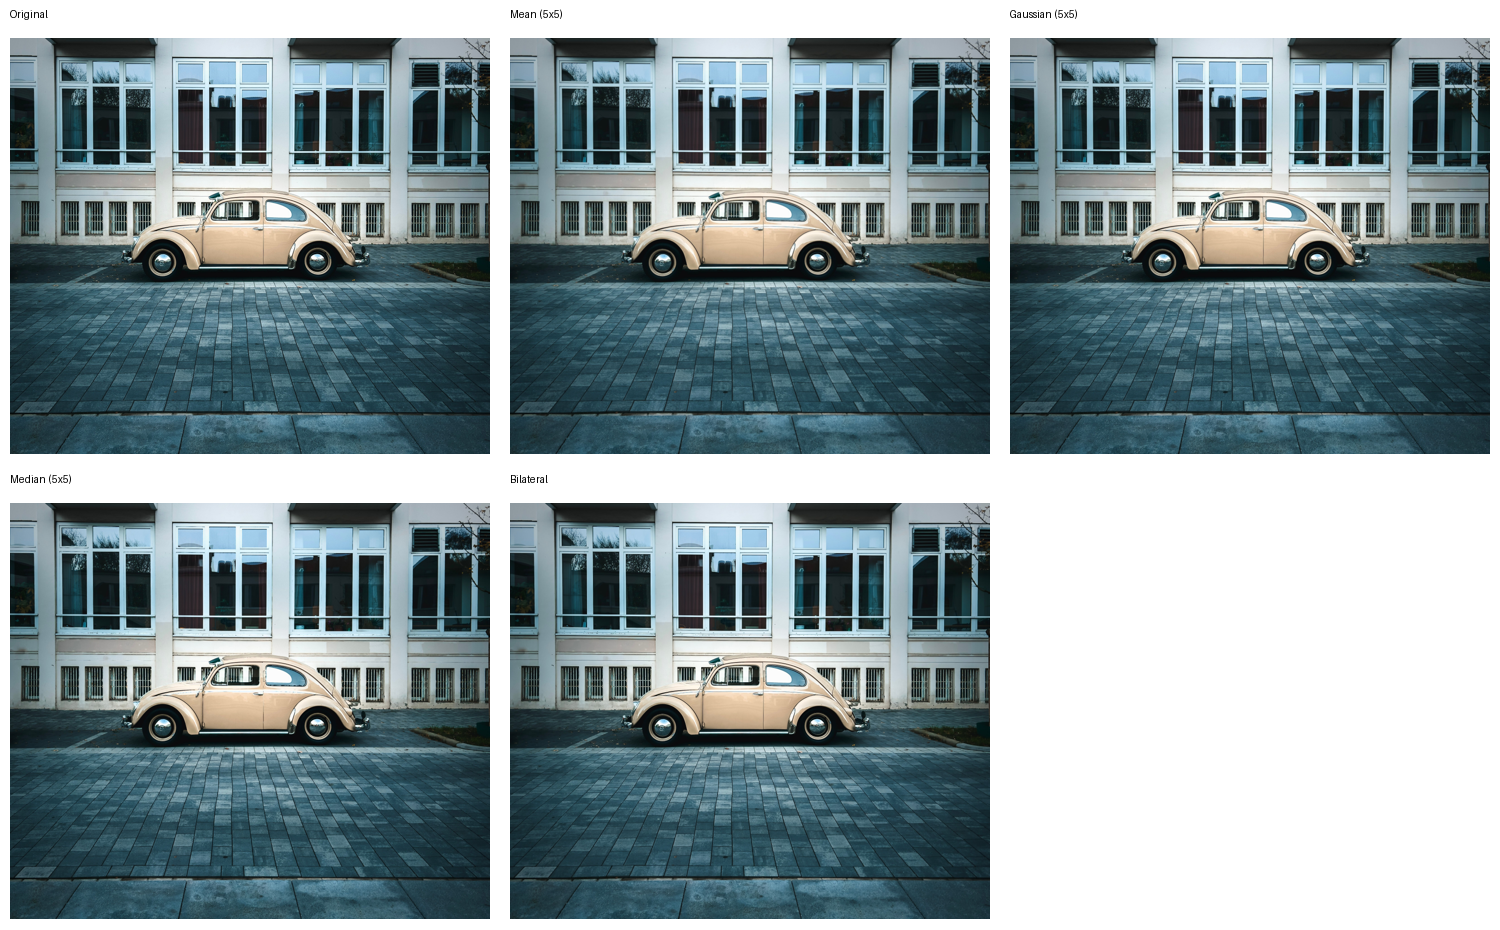


Đã lưu ảnh so sánh: comparison_filters.jpg
Laplacian càng cao thường càng giữ nhiều cạnh; MAE càng cao nghĩa là ảnh thay đổi nhiều hơn.


In [21]:
# So sánh các bộ lọc độc lập trên cùng ảnh gốc.
import cv2
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display

image = cv2.imread("lab2_pic.jpg", cv2.IMREAD_COLOR)
if image is None:
    raise FileNotFoundError("Không tìm thấy lab2_pic.jpg trong thư mục notebook.")

filtered_images = {
    "Original": image,
    "Mean (5x5)": cv2.blur(image, (5, 5)),
    "Gaussian (5x5)": cv2.GaussianBlur(image, (5, 5), 0),
    "Median (5x5)": cv2.medianBlur(image, 5),
    "Bilateral": cv2.bilateralFilter(image, 9, 75, 75),
}

# Tạo ảnh ghép để các kết quả có thể so sánh trực tiếp.
cell_width, cell_height = 500, 465
columns = 3
rows = (len(filtered_images) + columns - 1) // columns
comparison = Image.new("RGB", (columns * cell_width, rows * cell_height), "white")
draw = ImageDraw.Draw(comparison)

gray_original = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
original_float = gray_original.astype(np.float32)
print(f"{'Bộ lọc':<18} {'Độ sắc nét (Laplacian)':>25} {'MAE so với gốc':>20}")
print("-" * 66)

for index, (name, filtered) in enumerate(filtered_images.items()):
    row, column = divmod(index, columns)
    x, y = column * cell_width, row * cell_height
    draw.text((x + 10, y + 8), name, fill="black")

    rgb = cv2.cvtColor(filtered, cv2.COLOR_BGR2RGB)
    thumbnail = Image.fromarray(rgb)
    thumbnail.thumbnail((cell_width - 20, cell_height - 45))
    comparison.paste(thumbnail, (x + 10, y + 38))

    gray = cv2.cvtColor(filtered, cv2.COLOR_BGR2GRAY)
    sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()
    mae = np.abs(gray.astype(np.float32) - original_float).mean()
    print(f"{name:<18} {sharpness:>25.2f} {mae:>20.2f}")

comparison.save("comparison_filters.jpg", quality=95)
display(comparison)
print("\nĐã lưu ảnh so sánh: comparison_filters.jpg")
print("Laplacian càng cao thường càng giữ nhiều cạnh; MAE càng cao nghĩa là ảnh thay đổi nhiều hơn.")

## Áp dụng lọc phi tuyến tính: Median và Bilateral

Khác với Mean/Gaussian (tổng có trọng số cố định nên là lọc tuyến tính), lọc phi tuyến tính không thể biểu diễn đơn giản bằng phép tích chập tuyến tính.

- **Median filter** thay giá trị mỗi pixel bằng trung vị các pixel trong cửa sổ lân cận. Nó hiệu quả với nhiễu muối tiêu (pixel đen/trắng đột biến) và thường ít làm nhòe biên hơn phép lấy trung bình. Kích thước cửa sổ phải là số lẻ; cửa sổ lớn có thể xóa chi tiết nhỏ.
- **Bilateral filter** tính trung bình có trọng số theo cả khoảng cách không gian và độ tương đồng màu/cường độ. Pixel ở xa hoặc khác màu nhiều có trọng số nhỏ, nên bộ lọc làm mượt vùng đồng nhất nhưng giữ biên tương đối tốt. Hai tham số `sigmaColor` và `sigmaSpace` điều khiển độ nhạy màu và phạm vi không gian.

Ví dụ dưới đây tạo nhiễu muối tiêu giả lập có seed cố định trên ảnh gốc, rồi áp dụng Median và Bilateral độc lập lên cùng ảnh nhiễu. MSE được tính so với ảnh gốc; càng thấp càng ít sai khác ở điểm ảnh. Bộ lọc Bilateral không được thiết kế chuyên để loại bỏ nhiễu xung, nên kết quả này cũng minh họa vì sao cần chọn bộ lọc theo loại nhiễu.

Kết quả                  MSE so với ảnh gốc     Độ sắc nét Laplacian
--------------------------------------------------------------------
Ảnh gốc                                0.00                  1358.56
Nhiễu muối tiêu                      876.49                 18441.16
Median (5x5)                         236.81                   404.09
Bilateral                            874.69                 17154.71


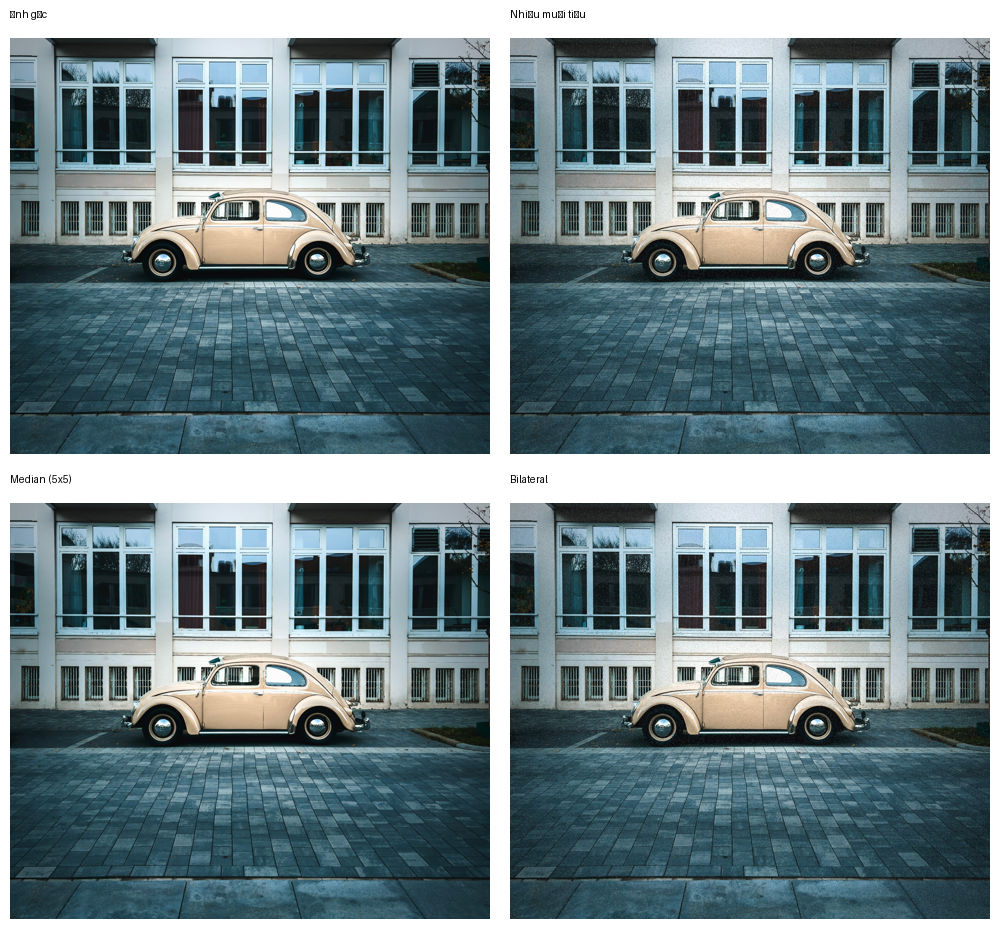


Đã lưu ảnh minh họa: nonlinear_filter_demo.jpg


In [22]:
import cv2
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display

original = cv2.imread("lab2_pic.jpg", cv2.IMREAD_COLOR)
if original is None:
    raise FileNotFoundError("Không tìm thấy lab2_pic.jpg trong thư mục notebook.")

# Thêm nhiễu muối tiêu lên 4% pixel; seed giúp tái lập kết quả.
rng = np.random.default_rng(42)
noisy = original.copy()
noise_mask = rng.random(original.shape[:2]) < 0.04
salt_mask = rng.random(original.shape[:2]) < 0.5
noisy[noise_mask & salt_mask] = 255
noisy[noise_mask & ~salt_mask] = 0

# Áp dụng độc lập trên cùng ảnh bị nhiễu.
median_result = cv2.medianBlur(noisy, 5)
bilateral_result = cv2.bilateralFilter(noisy, d=9, sigmaColor=75, sigmaSpace=75)
results = {
    "Ảnh gốc": original,
    "Nhiễu muối tiêu": noisy,
    "Median (5x5)": median_result,
    "Bilateral": bilateral_result,
}

# Ghép ảnh để quan sát đồng thời cả khả năng khử nhiễu và giữ biên.
panel_width, panel_height = 500, 465
comparison = Image.new("RGB", (panel_width * 2, panel_height * 2), "white")
draw = ImageDraw.Draw(comparison)

print(f"{'Kết quả':<22} {'MSE so với ảnh gốc':>20} {'Độ sắc nét Laplacian':>24}")
print("-" * 68)
for index, (name, result) in enumerate(results.items()):
    row, column = divmod(index, 2)
    x, y = column * panel_width, row * panel_height
    draw.text((x + 10, y + 8), name, fill="black")

    rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
    thumbnail = Image.fromarray(rgb)
    thumbnail.thumbnail((panel_width - 20, panel_height - 45))
    comparison.paste(thumbnail, (x + 10, y + 38))

    mse = np.mean((result.astype(np.float32) - original.astype(np.float32)) ** 2)
    gray = cv2.cvtColor(result, cv2.COLOR_BGR2GRAY)
    sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()
    print(f"{name:<22} {mse:>20.2f} {sharpness:>24.2f}")

comparison.save("nonlinear_filter_demo.jpg", quality=95)
display(comparison)
print("\nĐã lưu ảnh minh họa: nonlinear_filter_demo.jpg")